## Setup

In [1]:
# If anything is missing, uncomment:
# %pip install pandas numpy scipy statsmodels matplotlib


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy import stats, signal
from scipy.optimize import minimize_scalar
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.float_format", lambda x: f"{x:.6f}")


## Config — set Paths

In [3]:
import os

#  project root 
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

INDICES_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_daily_indices.csv"
SUMMARY_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_summary.csv"        

## Load data

### Index 

In [4]:
import os
from pathlib import Path

#  project root 
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

#  Submission Ready root 
SUBMISSION_ROOT = Path(os.environ.get(
    "SUBMISSION_ROOT", str(Path.home() / "Desktop" / "PCRA Index Thesis")
)).resolve()


INDICES_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_daily_indices.csv")
SUMMARY_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_summary.csv")

STAGE_A_DIRS = [
    SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected"
    / "Stage A" / "Full Data",
]

StageB_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected")

figdir = SUBMISSION_ROOT / "Visuals" / "Placebo"
figdir.mkdir(parents=True, exist_ok=True)

print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  Indices: {INDICES_PATH}  {'✓' if INDICES_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Summary: {SUMMARY_PATH}  {'✓' if SUMMARY_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Figures: {figdir}  {'✓ created/exists' if figdir.exists() else '✗ FAILED'}")

SUBMISSION_ROOT: /Users/adam/Desktop/PCRA Index Thesis  ✓
  Indices: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_daily_indices.csv  ✓
  Summary: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_summary.csv  ✓
  Figures: /Users/adam/Desktop/PCRA Index Thesis/Visuals/Placebo  ✓ created/exists


### Derived financial-data paths

In [5]:
from pathlib import Path

# Derived paths 
EMDAT_DIR = SUBMISSION_ROOT / "Financial Data" / "Disaster"
EPU_DIR   = SUBMISSION_ROOT / "Financial Data" / "Other Indices"

# Country name --> ISO code for EM-DAT filenames
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

# Verify expected paths exist
print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  EM-DAT:    {EMDAT_DIR}  {'✓' if EMDAT_DIR.exists() else '✗ NOT FOUND'}")
print(f"  Other Idx: {EPU_DIR}  {'✓' if EPU_DIR.exists() else '✗ NOT FOUND'}")

SUBMISSION_ROOT: /Users/adam/Desktop/PCRA Index Thesis  ✓
  EM-DAT:    /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Disaster  ✓
  Other Idx: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices  ✓


In [ ]:
# Path 
EPU_PATH = EPU_DIR / "All_Daily_Policy_Data.csv"

print(f"  EPU path: {EPU_PATH}")
print(f"  Exists  : {'✓' if EPU_PATH.exists() else '✗ NOT FOUND'}")

if not EPU_PATH.exists():
    raise FileNotFoundError(
        f"EPU file not found at {EPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + "\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
        if EPU_DIR.exists() else
        f"EPU file not found at {EPU_PATH}\nOther Indices folder itself doesn't exist: {EPU_DIR}"
    )


epu_raw = pd.read_csv(EPU_PATH)
print(f"\n✓ Loaded EPU: {len(epu_raw):,} rows")
print(f"  Columns: {list(epu_raw.columns)}")

#  Build date from year  month  day 

epu_raw["date"] = pd.to_datetime({
    "year":  epu_raw["year"].astype(int),
    "month": epu_raw["month"].astype(int),
    "day":   epu_raw["day"].astype(int),
}, errors="coerce")

#  Clean & filter 

epu_df = epu_raw[["date", "daily_policy_index"]].copy()
epu_df.columns = ["date", "epu"]
epu_df["epu"] = pd.to_numeric(epu_df["epu"], errors="coerce")
epu_df = epu_df.dropna(subset=["date", "epu"])

epu_df = epu_df[
    (epu_df["date"] >= "2008-01-01") &
    (epu_df["date"] <= "2025-12-31")
].sort_values("date").reset_index(drop=True)

# summary

print(f"\n✓ epu_df ready")
print(f"  Observations : {len(epu_df):,}")
print(f"  Date range   : {epu_df['date'].min().date()} "
      f"→ {epu_df['date'].max().date()}")
print(f"  Mean EPU     : {epu_df['epu'].mean():.2f}")
print(f"  Max EPU      : {epu_df['epu'].max():.2f}")

display(epu_df.head())

  EPU path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices/All_Daily_Policy_Data.csv
  Exists  : ✓

✓ Loaded EPU: 15,125 rows
  Columns: ['day', 'month', 'year', 'daily_policy_index']

✓ epu_df ready
  Observations : 6,575
  Date range   : 2008-01-01 → 2025-12-31
  Mean EPU     : 144.66
  Max EPU      : 1026.38


,date,epu
0,2008-01-01,232.870000
1,2008-01-02,83.140000
2,2008-01-03,189.340000
3,2008-01-04,103.240000
4,2008-01-05,281.750000


In [7]:

#  EM-DAT file 
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

print(f"  EM-DAT US path: {EMDAT_FILES['US']}")
print(f"  Exists        : {'✓' if EMDAT_FILES['US'].exists() else '✗ NOT FOUND'}")

if not EMDAT_FILES["US"].exists():
    raise FileNotFoundError(
        f"EM-DAT file not found at {EMDAT_FILES['US']}\n"
        f"Files currently in EM-DAT folder:\n"
        + ("\n".join(f"  {f.name}" for f in EMDAT_DIR.iterdir())
           if EMDAT_DIR.exists() else f"  (folder itself doesn't exist: {EMDAT_DIR})")
    )

#  Load US EM-DAT file 

emdat_raw = pd.read_excel(EMDAT_FILES["US"])
print(f"\n✓ Loaded EM-DAT US: {len(emdat_raw):,} rows")
print(f"  Columns: {list(emdat_raw.columns)}")

#  Identify date column 

if "Start Year" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime({
        "year":  emdat_raw["Start Year"].fillna(0).astype(int),
        "month": emdat_raw["Start Month"].fillna(1).astype(int),
        "day":   emdat_raw["Start Day"].fillna(1).astype(int),
    }, errors="coerce")
elif "Disaster Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Disaster Date"], errors="coerce")
elif "Event Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Event Date"], errors="coerce")
else:
    raise RuntimeError(
        f"Cannot find a date column in EM-DAT. "
        f"Available columns: {list(emdat_raw.columns)}")

#  Filter to sample period & drop undated rows 

emdat_us = emdat_raw.dropna(subset=["event_date"]).copy()
emdat_us = emdat_us[
    (emdat_us["event_date"] >= "2008-01-01") &
    (emdat_us["event_date"] <= "2025-12-31")
].reset_index(drop=True)

print(f"  After date filter (2008–2025): {len(emdat_us):,} events")

#  Build emdat_dates 

emdat_dates = pd.to_datetime(
    emdat_us["event_date"].dropna().values,
    errors="coerce"
)
emdat_dates = emdat_dates[~pd.isnull(emdat_dates)]

print(f"  emdat_dates ready : {len(emdat_dates):,} dates")

# Build EMDAT_EVENTS 

_desc_col = next(
    (c for c in ["Disaster Type", "Event Name", "Disaster Subtype", "Type"]
     if c in emdat_us.columns), None)

_type_col = next(
    (c for c in ["Disaster Subtype", "Disaster Type", "Event Type"]
     if c in emdat_us.columns), None)

_chronic_terms = [
    "drought", "sea level", "heat stress", "extreme temperature",
    "cold wave", "heat wave", "wildfire", "land fire"
]

def _classify_type(row):
    if _type_col is None:
        return "acute"
    val = str(row[_type_col]).lower()
    return "chronic" if any(t in val for t in _chronic_terms) else "acute"

emdat_us["etype"] = emdat_us.apply(_classify_type, axis=1)

if _desc_col:
    EMDAT_EVENTS = list(zip(
        emdat_us["event_date"].dt.strftime("%Y-%m-%d"),
        emdat_us[_desc_col].fillna("Unknown"),
        emdat_us["etype"]
    ))
else:
    EMDAT_EVENTS = list(zip(
        emdat_us["event_date"].dt.strftime("%Y-%m-%d"),
        ["Event"] * len(emdat_us),
        emdat_us["etype"]
    ))

print(f"  EMDAT_EVENTS ready: {len(EMDAT_EVENTS):,} entries "
      f"({emdat_us['etype'].eq('acute').sum():,} acute, "
      f"{emdat_us['etype'].eq('chronic').sum():,} chronic)")

  EM-DAT US path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Disaster/EMDAT_US.xlsx
  Exists        : ✓

✓ Loaded EM-DAT US: 417 rows
  Columns: ['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update']
  After date filter 

In [8]:
#  Path 
CPU_PATH = EPU_DIR / "cpu_pu.xlsx"
print(f"  CPU path: {CPU_PATH}")
print(f"  Exists  : {'✓' if CPU_PATH.exists() else '✗ NOT FOUND'}")

if not CPU_PATH.exists():
    raise FileNotFoundError(
        f"CPU file not found at {CPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + ("\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
           if EPU_DIR.exists() else f"  (folder itself doesn't exist: {EPU_DIR})"))

#  Inspect sheets 
xl = pd.ExcelFile(CPU_PATH)
print(f"\n  Sheets available: {xl.sheet_names}")

#  Load sheet 2 data
cpu_raw = pd.read_excel(
    CPU_PATH,
    sheet_name=xl.sheet_names[1],
    dtype={"date": str})

print(f"\n✓ Loaded CPU from sheet: '{xl.sheet_names[1]}'")
print(f"  Rows              : {len(cpu_raw):,}")
print(f"  Columns           : {list(cpu_raw.columns)}")
print(f"  Date sample (raw) : {cpu_raw['date'].head(5).tolist()}")
display(cpu_raw.head(5))

#  Build date 
cpu_raw["date"] = pd.to_datetime(
    cpu_raw["date"].astype(str).str.strip().str.replace("M", "-") + "-01",
    format="%Y-%m-%d",
    errors="coerce"
)
print(f"\n  Date sample (parsed): {cpu_raw['date'].dropna().head(3).tolist()}")

#  Select index columns 
cpu_value_cols = [c for c in cpu_raw.columns if c not in
                  ["year", "month", "day", "date"]]
print(f"  CPU value columns found: {cpu_value_cols}")

cpu_df = cpu_raw[["date"] + cpu_value_cols].copy()

#  Standardise column names 
rename_map = {}
for col in cpu_value_cols:
    col_lower = col.lower()
    if "narrow" in col_lower and "news" not in col_lower:
        rename_map[col] = "cpu_index_narrow"
    elif "broad" in col_lower and "news" not in col_lower:
        rename_map[col] = "cpu_index_broad"
    elif "gavriilidis" in col_lower or col_lower in ["cpu", "cpu_index"]:
        rename_map[col] = "cpu_index_gavriilidis"
    elif "news" in col_lower and "narrow" in col_lower:
        rename_map[col] = "cpnews_index_narrow"
    elif "news" in col_lower and "broad" in col_lower:
        rename_map[col] = "cpnews_index_broad"
    elif "sent" in col_lower:
        rename_map[col] = "cpsent_index"
    elif "instrument" in col_lower:
        rename_map[col] = "cpu_instrument"
    elif "shock" in col_lower:
        rename_map[col] = "cpu_shock"

if rename_map:
    cpu_df = cpu_df.rename(columns=rename_map)
    print(f"  Renamed columns: {rename_map}")

#  Convert value columns to numeric 
for col in cpu_df.columns:
    if col != "date":
        cpu_df[col] = pd.to_numeric(cpu_df[col], errors="coerce")

cpu_df = (cpu_df
    .dropna(subset=["date"])
    .loc[lambda d: (d["date"] >= "2008-01-01") & (d["date"] <= "2025-12-31")]
    .sort_values("date")
    .reset_index(drop=True))

#  Summary 
print(f"\n✓ cpu_df ready")
print(f"  Observations : {len(cpu_df):,}")
print(f"  Date range   : {cpu_df['date'].min().date()} "
      f"→ {cpu_df['date'].max().date()}")
print(f"  Columns      : {list(cpu_df.columns)}")
for col in cpu_df.columns:
    if col != "date":
        non_null = cpu_df[col].dropna()
        if len(non_null) > 0:
            print(f"  {col:<30s} mean={non_null.mean():.2f}  "
                  f"max={non_null.max():.2f}  "
                  f"n={len(non_null):,}")
        else:
            print(f"  {col:<30s} all NaN")
display(cpu_df.head())

  CPU path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices/cpu_pu.xlsx
  Exists  : ✓

  Sheets available: ['readme', 'data']

✓ Loaded CPU from sheet: 'data'
  Rows              : 492
  Columns           : ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  Date sample (raw) : ['1985M01', '1985M02', '1985M03', '1985M04', '1985M05']


,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock
0,1985M01,35.469868,67.558322,NaN,52.560527,54.654046,146.698243,NaN,NaN
1,1985M02,12.957033,16.960149,NaN,51.736757,51.679215,98.249098,NaN,NaN
2,1985M03,35.618421,61.085415,NaN,60.033463,58.400578,229.254864,NaN,NaN
3,1985M04,59.485346,48.462095,NaN,47.960487,51.492845,178.405419,NaN,NaN
4,1985M05,26.375457,34.621114,NaN,46.887293,49.883908,90.879046,NaN,NaN



  Date sample (parsed): [Timestamp('1985-01-01 00:00:00'), Timestamp('1985-02-01 00:00:00'), Timestamp('1985-03-01 00:00:00')]
  CPU value columns found: ['cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  Renamed columns: {'cpu_index_narrow': 'cpu_index_narrow', 'cpu_index_broad': 'cpu_index_broad', 'cpu_index_gavriilidis': 'cpu_index_gavriilidis', 'cpnews_index_narrow': 'cpnews_index_narrow', 'cpnews_index_broad': 'cpnews_index_broad', 'cpsent_index': 'cpsent_index', 'cpu_instrument': 'cpu_instrument', 'cpu_shock': 'cpu_shock'}

✓ cpu_df ready
  Observations : 216
  Date range   : 2008-01-01 → 2025-12-01
  Columns      : ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  cpu_index_narrow               mean=258.70  max=916.28  n=216
  cpu_index_broad               

,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock
0,2008-01-01,165.633687,139.253340,94.648509,142.021777,116.369936,95.839287,0.000000,0.325613
1,2008-02-01,143.749401,122.719308,96.943516,115.694766,104.871164,108.800735,0.000000,0.219075
2,2008-03-01,111.876447,75.812874,55.128163,129.749332,106.656863,168.340079,0.000000,-0.571754
3,2008-04-01,143.723709,125.556904,93.901780,149.634044,129.335019,183.769227,0.000000,0.479395
4,2008-05-01,153.042190,127.720523,85.667217,140.454251,128.767182,130.668079,-0.274189,0.681724


In [9]:
#  Load combined daily indices 
df = pd.read_csv(INDICES_PATH)
df["date"] = pd.to_datetime(df["date"])

print(f"  Loaded : {len(df):,} rows")
print(f"  Columns: {list(df.columns)}")
print(f"  Range  : {df['date'].min().date()} → {df['date'].max().date()}")

#  Rename DSP --> CSP 
if "DSP" not in df.columns:
    raise KeyError(f"Expected column 'DSP' not found. Columns present: {list(df.columns)}")
df = df.rename(columns={"DSP": "CSP"})

  Loaded : 4,697 rows
  Columns: ['date', 'country', 'S_daily_raw', 'S_daily', 'SSI', 'DSP']
  Range  : 2008-01-01 → 2025-12-31


## Helpers

In [10]:
@dataclass
class CheckResult:
    name: str
    passed: bool | None
    value: str
    note: str = ""

    def show(self):
        if self.passed is None:
            tag = "[ INFO ]"
        elif self.passed:
            tag = "[ PASS ]"
        else:
            tag = "[ FAIL ]"
        print(f"{tag}  {self.name:55s}  {self.value}")
        if self.note:
            print(f"          note: {self.note}")


def ewma(x: np.ndarray, lam: float, init: float | None = None) -> np.ndarray:
    #SSI_t = lam*SSI_{t-1} + (1-lam)*S_t (proposal Phase 3)
    out = np.empty_like(x, dtype=float)
    out[0] = init if init is not None else x[0]
    for i in range(1, len(x)):
        out[i] = lam * out[i - 1] + (1.0 - lam) * x[i]
    return out


def kpss_safe(series, regression="c"):
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(series, regression=regression, nlags="auto")
    return stat, p


def hl_to_lambda(hl: int) -> float:
    #Half-life (business days) -> EWMA lambda. lambda^h = 1/2
    return float(2.0 ** (-1.0 / hl))


def distance_correlation(x: np.ndarray, y: np.ndarray) -> float:
    #Szekely-Rizzo-Bakirov distance correlation. O(n^2)
    x = np.asarray(x, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)
    a = np.abs(x[:, None] - x[None, :])
    b = np.abs(y[:, None] - y[None, :])
    A = a - a.mean(0) - a.mean(1)[:, None] + a.mean()
    B = b - b.mean(0) - b.mean(1)[:, None] + b.mean()
    dcov2 = (A * B).mean()
    dvar_x = (A * A).mean()
    dvar_y = (B * B).mean()
    if dvar_x <= 0 or dvar_y <= 0:
        return 0.0
    return float(np.sqrt(max(dcov2, 0.0)) / np.sqrt(np.sqrt(dvar_x * dvar_y)))

results: list[CheckResult] = []

In [11]:
def ewma(x, lam, init=None):
    out = np.empty_like(x, dtype=float)
    out[0] = init if init is not None else x[0]
    for i in range(1, len(x)):
        out[i] = lam * out[i - 1] + (1.0 - lam) * x[i]
    return out


def kpss_safe(series, regression="c"):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(series, regression=regression, nlags="auto")
    return stat, p


def variance_ratio(x, q):
    """Lo-MacKinlay variance ratio test. VR(q) and asymptotic z-stat."""
    n = len(x)
    mu = (x[-1] - x[0]) / n
    # sigma_1^2
    s1 = np.sum((x[1:] - x[:-1] - mu) ** 2) / (n - 1)
    # sigma_q^2
    diffs_q = x[q:] - x[:-q] - q * mu
    sq = np.sum(diffs_q ** 2) / (n - q)
    vr = sq / (q * s1) if s1 > 0 else np.nan
    # Asymptotic z under homoscedasticity
    z = (vr - 1) / np.sqrt(2 * (q - 1) / (3 * q * n)) if not np.isnan(vr) else np.nan
    return float(vr), float(z)

# Placebo

## Placebo Construction

### Scoring + Sentiment List

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path

StageB_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected")

#  Check scored_full 
try:
    assert "scored_full" in globals() and not scored_full.empty
    print(f"✓ scored_full in scope: {len(scored_full):,} rows")
except AssertionError:
    SCORED_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 2 - Article Scoring"
                   / "US_full_period_phase2_scored.csv")
    print(f"  Loading from: {SCORED_PATH}")
    scored_full = pd.read_csv(SCORED_PATH)
    if "assigned_date" in scored_full.columns and "date" not in scored_full.columns:
        scored_full = scored_full.rename(columns={"assigned_date": "date"})
    scored_full["date"] = pd.to_datetime(scored_full["date"], errors="coerce")
    print(f"✓ scored_full loaded: {len(scored_full):,} rows")

print(f"  Columns: {list(scored_full.columns[:8])}")

#  LM Negative lexicon 
LM_DICT_PATH = (SUBMISSION_ROOT / "Financial Data" / "Sentiment"
                / "Loughran-McDonald_MasterDictionary_1993-2025.csv")

if not LM_DICT_PATH.exists():
    raise FileNotFoundError(
        f"LM master dictionary not found at {LM_DICT_PATH}")

_lm_df = pd.read_csv(LM_DICT_PATH)
lm_neg = set(
    _lm_df.loc[_lm_df["Negative"] > 0, "Word"]
    .str.lower().str.strip().tolist())
print(f"✓ LM negative terms loaded: {len(lm_neg):,}")

#  Check articles with body text 
try:
    assert "articles" in globals() and not articles.empty
    print(f"✓ articles in scope: {len(articles):,} rows")
except AssertionError:
    STAGEB_PATH = StageB_PATH / "Stage B" / "US_full_period_stageB_combined.csv"
    if not STAGEB_PATH.exists():
        raise FileNotFoundError(
            f"StageB file not found at {STAGEB_PATH}\n"
            f"Files in Stage B folder:\n"
            + ("\n".join(f"  {f.name}" for f in (StageB_PATH / 'Stage B').iterdir())
               if (StageB_PATH / "Stage B").exists()
               else f"  (Stage B folder itself doesn't exist: {StageB_PATH / 'Stage B'})")
        )
    articles = pd.read_csv(
        STAGEB_PATH,
        usecols=["story_id", "assigned_date", "text"],
        parse_dates=["assigned_date"]
    ).rename(columns={"assigned_date": "date", "text": "body_text"})
    print(f"✓ articles loaded: {len(articles):,} rows")

  Loading from: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 2 - Article Scoring/US_full_period_phase2_scored.csv
✓ scored_full loaded: 41,920 rows
  Columns: ['story_id', 'country', 'score', 'n_hits', 'n_unique_terms', 'sum_contributions', 'length_norm', 'article_length']
✓ LM negative terms loaded: 2,345
✓ articles loaded: 41,920 rows


### Score articles with LM negative lexicon

In [13]:
import re

def score_lm_placebo(text: str, lm_neg_set: set) -> float:
    """
    Count LM negative terms per article, length-normalised (alpha=0.5)
    following Loughran and McDonald (2011).
    """
    if not isinstance(text, str) or len(text) < 10:
        return 0.0
    tokens = re.findall(r"[a-z]+", text.lower())
    if len(tokens) == 0:
        return 0.0
    hits = sum(1 for t in tokens if t in lm_neg_set)
    return hits / (len(tokens) ** 0.5)

corpus_lm = scored_full[["story_id", "date"]].merge(
    articles[["story_id", "body_text"]],
    on="story_id", how="inner")

print(f"  Articles with body text : {len(corpus_lm):,}")
print("  Scoring with LM negative lexicon...")

corpus_lm["S_lm"] = corpus_lm["body_text"].apply(
    lambda x: score_lm_placebo(x, lm_neg))

print(f"  Non-zero LM scores      : {(corpus_lm['S_lm'] > 0).sum():,}")
print(f"  Mean LM score           : {corpus_lm['S_lm'].mean():.6f}")
corpus_lm.head(3)

  Articles with body text : 41,920
  Scoring with LM negative lexicon...
  Non-zero LM scores      : 40,721
  Mean LM score           : 0.539545


,story_id,date,body_text,S_lm
0,78d9165e7770cc24a4a99b2c50ef1cda49d156606b8ed0...,2008-01-01,"On New Year’s Day, let us contemplate signs of...",0.592157
1,53c704e3ff750b03b11cf02a5a47684ff05bf89294d4be...,2008-01-22,I have a story in Science Times looking at the...,0.495896
2,bb698d0704d3c7a558913f4ff504a41c400ae8a13455a8...,2008-01-28,Landslide margins among black voters powered B...,0.306719


### Aggregate to daily LM score

In [14]:
lm_daily = (corpus_lm
    .groupby("date")["S_lm"]
    .mean()
    .reset_index()
    .rename(columns={"S_lm": "S_lm_daily"}))

lm_daily["date"] = pd.to_datetime(lm_daily["date"])
lm_daily = lm_daily.sort_values("date").reset_index(drop=True)

print(f"  Daily LM obs  : {len(lm_daily):,}")
print(f"  Date range    : {lm_daily['date'].min()} → {lm_daily['date'].max()}")
print(f"  Mean          : {lm_daily['S_lm_daily'].mean():.6f}")
print(f"  Std           : {lm_daily['S_lm_daily'].std():.6f}")
print(f"  rho(1)        : {lm_daily['S_lm_daily'].autocorr(1):.4f}")
lm_daily.head()

  Daily LM obs  : 4,110
  Date range    : 2008-01-01 00:00:00 → 2025-12-31 00:00:00
  Mean          : 0.578511
  Std           : 0.239540
  rho(1)        : 0.1332


,date,S_lm_daily
0,2008-01-01,0.592157
1,2008-01-22,0.495896
2,2008-01-28,0.306719
3,2008-01-29,0.234978
4,2008-01-30,0.471027


### Construct LM SSI and CSP

In [15]:
import warnings
from statsmodels.tsa.ar_model import AutoReg

LAMBDA      = 0.977
ROLL_WINDOW = 252
MIN_PERIODS = 60

# SSI
s_lm = lm_daily["S_lm_daily"].fillna(0.0).values

lm_ssi = np.empty(len(s_lm))
lm_ssi[0] = s_lm[0]
for i in range(1, len(s_lm)):
    v = s_lm[i] if not np.isnan(s_lm[i]) else 0.0
    lm_ssi[i] = LAMBDA * lm_ssi[i-1] + (1 - LAMBDA) * v

lm_daily["LM_SSI"]      = lm_ssi
lm_daily["LM_SSI_lag1"] = lm_daily["LM_SSI"].shift(1)

#  State-adjusted score 
lm_daily["S_tilde"] = (lm_daily["S_lm_daily"].fillna(0.0)
                        - lm_daily["LM_SSI_lag1"])
s_tilde_lm = lm_daily["S_tilde"].dropna()

#  AR(p)  BIC selection 
best_bic, best_p, best_resid = np.inf, 0, None
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for p in range(0, 6):
        try:
            if p == 0:
                resid  = s_tilde_lm - s_tilde_lm.mean()
                n      = len(resid)
                sigma2 = float((resid ** 2).mean())
                bic    = n * np.log(sigma2) + np.log(n) * 1
            else:
                m     = AutoReg(s_tilde_lm.values, lags=p, old_names=False).fit()
                resid = pd.Series(m.resid, index=s_tilde_lm.index[p:])
                bic   = float(m.bic)
        except Exception:
            continue
        if bic < best_bic:
            best_bic, best_p, best_resid = bic, p, resid

#  Rolling standardise 
sd_roll   = best_resid.rolling(ROLL_WINDOW, min_periods=MIN_PERIODS).std()
lm_csp    = (best_resid / sd_roll).dropna()

lm_daily["LM_CSP"] = np.nan
lm_daily.loc[lm_csp.index, "LM_CSP"] = lm_csp.values

print(f"  Best AR order (BIC) : p = {best_p}")
print(f"  LM_CSP mean         : {lm_daily['LM_CSP'].dropna().mean():+.4f}")
print(f"  LM_CSP std          : {lm_daily['LM_CSP'].dropna().std():.4f}")
print(f"  LM_CSP rho(1)       : {lm_daily['LM_CSP'].dropna().autocorr(1):.4f}")

#  Correlation with PCRA CSP 
common = lm_daily.merge(df[["date", "CSP"]], on="date", how="inner").dropna(
    subset=["LM_CSP", "CSP"])
print(f"  Corr(LM_CSP, PCRA_CSP) : {common['LM_CSP'].corr(common['CSP']):.4f}")

  Best AR order (BIC) : p = 0
  LM_CSP mean         : +0.0006
  LM_CSP std          : 0.9744
  LM_CSP rho(1)       : 0.0847
  Corr(LM_CSP, PCRA_CSP) : -0.0252


## Placebo Validation

### EM-DAT coincidence permutation test — LM placebo

In [16]:
import numpy as np
import pandas as pd

for _name in ("lm_daily",):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run the LM_CSP cell first.")


if "EMDAT_DATES" in dir():
    _emdat_source = EMDAT_DATES
elif "emdat_dates" in dir():
    _emdat_source = emdat_dates
else:
    raise NameError(
        "Neither 'EMDAT_DATES' nor 'emdat_dates' is defined. "
        "Run the EM-DAT loading cell first."
    )

WINDOW        = 2
B             = 10_000
CSP_THRESHOLD = 1.5
RANDOM_STATE  = 42

# Pre-sort EM-DAT dates
emdat_arr = np.sort(np.array(
    pd.to_datetime(pd.Index(_emdat_source)), dtype="datetime64[D]"))

def count_matches_fast(shock_dates_arr, event_dates_sorted, window_days):
    w  = np.timedelta64(window_days, 'D')
    lo = np.searchsorted(event_dates_sorted, shock_dates_arr - w, side="left")
    hi = np.searchsorted(event_dates_sorted, shock_dates_arr + w, side="right")
    return int(np.sum(hi > lo))

#  LM placebo coincidence 
lm_sub        = lm_daily.dropna(subset=["LM_CSP"]).reset_index(drop=True)
lm_shock_arr  = np.array(
    pd.to_datetime(lm_sub.loc[lm_sub["LM_CSP"].abs() >= CSP_THRESHOLD, "date"].values),
    dtype="datetime64[D]")
lm_all_arr    = np.array(pd.to_datetime(lm_sub["date"].values), dtype="datetime64[D]")

if len(lm_shock_arr) == 0:
    raise RuntimeError(
        f"No LM_CSP observations exceed |LM_CSP| >= {CSP_THRESHOLD} — "
        "cannot run the placebo permutation test with zero shocks."
    )

lm_observed   = count_matches_fast(lm_shock_arr, emdat_arr, WINDOW)
lm_obs_rate   = lm_observed / len(lm_shock_arr)

rng = np.random.default_rng(RANDOM_STATE)
lm_null = np.array([
    count_matches_fast(
        rng.choice(lm_all_arr, size=len(lm_shock_arr), replace=False),
        emdat_arr, WINDOW)
    for _ in range(B)
])
lm_null_mean = lm_null.mean()
lm_null_rate = lm_null_mean / len(lm_shock_arr)
lm_p_val     = float((lm_null >= lm_observed).mean())

print("── LM Placebo — EM-DAT coincidence ──")
print(f"  Shocks |LM_CSP| >= {CSP_THRESHOLD} : {len(lm_shock_arr)}")
print(f"  Observed matches          : {lm_observed}/{len(lm_shock_arr)} ({lm_obs_rate:.1%})")
print(f"  Null mean                 : {lm_null_mean:.1f} ({lm_null_rate:.1%})")
print(f"  p-value                   : {lm_p_val:.4f}")
print(f"  Significant (p < 0.05)    : {'YES ✓' if lm_p_val < 0.05 else 'NO ✗'}")

── LM Placebo — EM-DAT coincidence ──
  Shocks |LM_CSP| >= 1.5 : 416
  Observed matches          : 103/416 (24.8%)
  Null mean                 : 118.3 (28.4%)
  p-value                   : 0.9664
  Significant (p < 0.05)    : NO ✗


In [17]:
#  PCRA CSP coincidence
pcra_sub       = df.dropna(subset=["CSP"]).reset_index(drop=True)
pcra_shock_arr = np.array(
    pd.to_datetime(pcra_sub.loc[pcra_sub["CSP"].abs() >= CSP_THRESHOLD, "date"].values),
    dtype="datetime64[D]")
pcra_all_arr   = np.array(pd.to_datetime(pcra_sub["date"].values), dtype="datetime64[D]")

pcra_observed  = count_matches_fast(pcra_shock_arr, emdat_arr, WINDOW)
pcra_obs_rate  = pcra_observed / len(pcra_shock_arr)

rng2 = np.random.default_rng(RANDOM_STATE)
pcra_null = np.array([
    count_matches_fast(
        rng2.choice(pcra_all_arr, size=len(pcra_shock_arr), replace=False),
        emdat_arr, WINDOW)
    for _ in range(B)
])
pcra_null_mean = pcra_null.mean()
pcra_null_rate = pcra_null_mean / len(pcra_shock_arr)
pcra_p_val     = float((pcra_null >= pcra_observed).mean())

print("\n── PCRA CSP — EM-DAT coincidence (for comparison) ──")
print(f"  Shocks |CSP| >= {CSP_THRESHOLD}    : {len(pcra_shock_arr)}")
print(f"  Observed matches          : {pcra_observed}/{len(pcra_shock_arr)} ({pcra_obs_rate:.1%})")
print(f"  Null mean                 : {pcra_null_mean:.1f} ({pcra_null_rate:.1%})")
print(f"  p-value                   : {pcra_p_val:.4f}")
print(f"  Significant (p < 0.05)    : {'YES ✓' if pcra_p_val < 0.05 else 'NO ✗'}")



── PCRA CSP — EM-DAT coincidence (for comparison) ──
  Shocks |CSP| >= 1.5    : 216
  Observed matches          : 73/216 (33.8%)
  Null mean                 : 59.6 (27.6%)
  p-value                   : 0.0221
  Significant (p < 0.05)    : YES ✓


In [18]:

print(f"\n── Comparison ──")
print(f"  PCRA CSP match rate : {pcra_obs_rate:.1%} (p = {pcra_p_val:.4f})")
print(f"  LM placebo match rate: {lm_obs_rate:.1%} (p = {lm_p_val:.4f})")
print(f"  {'✓ PCRA discriminates physical events better than LM placebo' if pcra_p_val < lm_p_val else '⚠ LM placebo performs comparably — review'}")


── Comparison ──
  PCRA CSP match rate : 33.8% (p = 0.0221)
  LM placebo match rate: 24.8% (p = 0.9664)
  ✓ PCRA discriminates physical events better than LM placebo


### PCA

In [19]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

#  Align CSP and LM_CSP on common dates
pca_df = (df[["date", "CSP"]]
    .merge(lm_daily[["date", "LM_CSP"]], on="date", how="inner")
    .dropna(subset=["CSP", "LM_CSP"])
    .reset_index(drop=True))

print(f"PCA columns    : ['CSP', 'LM_CSP']")
print(f"Complete rows  : {len(pca_df):,}")
print(f"Date range     : {pca_df['date'].min()} → {pca_df['date'].max()}")

#  Run PCA 
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(pca_df[["CSP", "LM_CSP"]])
pca      = PCA(n_components=2)
pca.fit(X_scaled)

var_df = pd.DataFrame(
    {"var_explained": pca.explained_variance_ratio_.round(3)},
    index=["PC1", "PC2"])
print("\nVariance explained per component:")
display(var_df)



PCA columns    : ['CSP', 'LM_CSP']
Complete rows  : 3,985
Date range     : 2008-12-18 00:00:00 → 2025-12-31 00:00:00

Variance explained per component:


,var_explained
PC1,0.513000
PC2,0.487000


In [20]:
loadings_df = pd.DataFrame(
    pca.components_.T.round(3),
    index=["CSP", "LM_CSP"],
    columns=["PC1", "PC2"])
print("\nLoadings (rows = variables, columns = principal components):")
display(loadings_df)


Loadings (rows = variables, columns = principal components):


,PC1,PC2
CSP,0.707000,0.707000
LM_CSP,-0.707000,0.707000


In [21]:
#  Interpretation 
pc1_var = pca.explained_variance_ratio_[0]
print(f"\nInterpretation:")
if pc1_var > 0.80:
    print(f"  PC1 explains {pc1_var:.1%} of variance — strong common factor.")
    print(f"  CSP and LM_CSP share substantial information.")
    print(f"  ⚠ Placebo not fully orthogonal to PCRA index.")
elif pc1_var > 0.55:
    print(f"  PC1 explains {pc1_var:.1%} of variance — moderate common factor.")
    print(f"  Some shared variation but each index retains a distinct component.")
else:
    print(f"  PC1 explains {pc1_var:.1%} of variance — near-equal split.")
    print(f"  ✓ CSP and LM_CSP are approximately orthogonal.")
    print(f"  ✓ PCRA index captures physical-risk-specific content not in LM sentiment.")


Interpretation:
  PC1 explains 51.3% of variance — near-equal split.
  ✓ CSP and LM_CSP are approximately orthogonal.
  ✓ PCRA index captures physical-risk-specific content not in LM sentiment.


### Visual Comparison

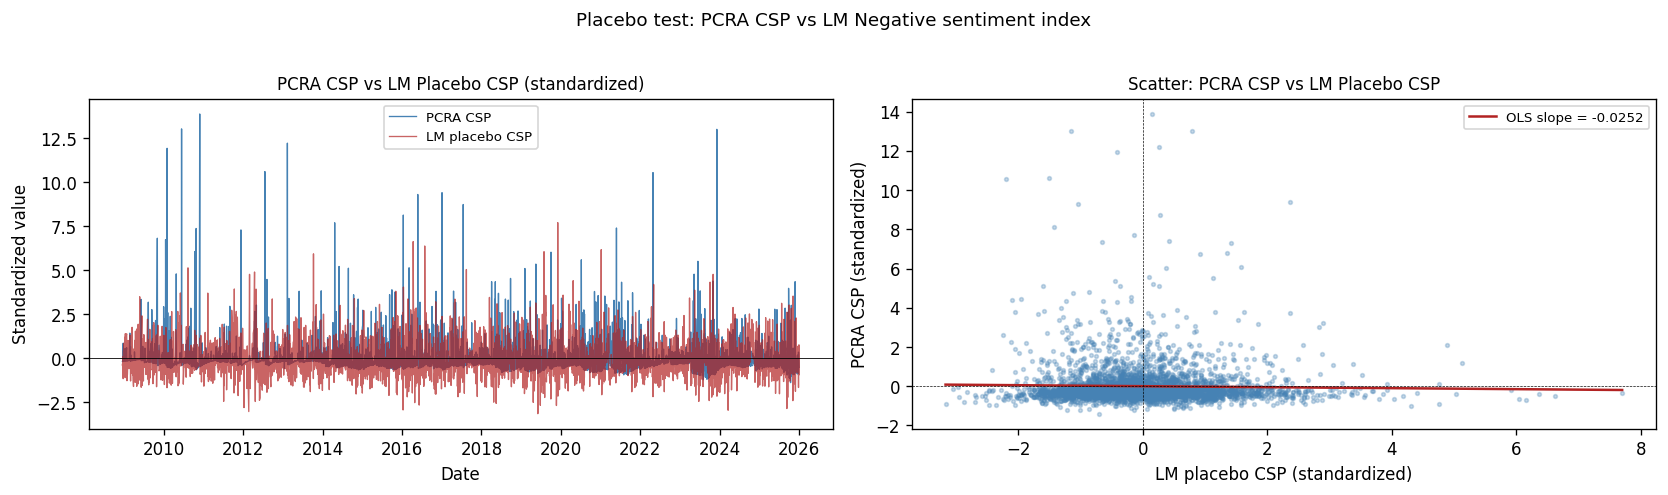

Pearson r  : -0.0252 (p = 0.1120)
Spearman r : -0.0013 (p = 0.9365)


In [22]:
pca_df["CSP_z"]    = ((pca_df["CSP"]    - pca_df["CSP"].mean())
                       / pca_df["CSP"].std())
pca_df["LM_CSP_z"] = ((pca_df["LM_CSP"] - pca_df["LM_CSP"].mean())
                       / pca_df["LM_CSP"].std())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

#  Panel 1: Time series 
axes[0].plot(pca_df["date"], pca_df["CSP_z"],
             label="PCRA CSP", lw=0.8, color="steelblue")
axes[0].plot(pca_df["date"], pca_df["LM_CSP_z"],
             label="LM placebo CSP", lw=0.8, color="firebrick", alpha=0.7)
axes[0].axhline(0, color="black", lw=0.5)
axes[0].set_title("PCRA CSP vs LM Placebo CSP (standardized)", fontsize=10)
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Standardized value")
axes[0].legend(fontsize=8)

#  Panel 2: Scatter 
axes[1].scatter(pca_df["LM_CSP_z"], pca_df["CSP_z"],
                s=5, alpha=0.3, color="steelblue")
m, b = np.polyfit(pca_df["LM_CSP_z"], pca_df["CSP_z"], 1)
x_range = np.linspace(pca_df["LM_CSP_z"].min(), pca_df["LM_CSP_z"].max(), 100)
axes[1].plot(x_range, m * x_range + b, color="firebrick", lw=1.5,
             label=f"OLS slope = {m:.4f}")
axes[1].axhline(0, color="black", lw=0.4, linestyle="--")
axes[1].axvline(0, color="black", lw=0.4, linestyle="--")
axes[1].set_xlabel("LM placebo CSP (standardized)")
axes[1].set_ylabel("PCRA CSP (standardized)")
axes[1].set_title("Scatter: PCRA CSP vs LM Placebo CSP", fontsize=10)
axes[1].legend(fontsize=8)

fig.suptitle("Placebo test: PCRA CSP vs LM Negative sentiment index",
             fontsize=11, y=1.02)
fig.tight_layout()
fig.savefig(figdir / "placebo_pca_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

#  Correlation 
from scipy.stats import pearsonr, spearmanr
pr, pp = pearsonr(pca_df["CSP"], pca_df["LM_CSP"])
sr, sp = spearmanr(pca_df["CSP"], pca_df["LM_CSP"])
print(f"Pearson r  : {pr:.4f} (p = {pp:.4f})")
print(f"Spearman r : {sr:.4f} (p = {sp:.4f})")

# Summary Table

In [23]:
pc1_var   = pca.explained_variance_ratio_[0]
pc2_var   = pca.explained_variance_ratio_[1]
csp_pc1   = float(loadings_df.loc["CSP",    "PC1"])
lm_pc1    = float(loadings_df.loc["LM_CSP", "PC1"])

placebo_summary = pd.DataFrame([
    {
        "test":           "EM-DAT coincidence (±2 days)",
        "PCRA_CSP":       f"{pcra_obs_rate:.1%} (p={pcra_p_val:.4f})",
        "LM_placebo":     f"{lm_obs_rate:.1%} (p={lm_p_val:.4f})",
        "interpretation": ("PCRA discriminates physical events; LM does not"
                           if pcra_p_val < 0.05 and lm_p_val >= 0.05
                           else "Both significant — partial overlap"
                           if pcra_p_val < 0.05 and lm_p_val < 0.05
                           else "Neither significant"),
    },
    {
        "test":           "PCA — variance explained by PC1",
        "PCRA_CSP":       f"Loading on PC1 = {csp_pc1:.3f}",
        "LM_placebo":     f"Loading on PC1 = {lm_pc1:.3f}",
        "interpretation": (f"PC1 = {pc1_var:.1%}, PC2 = {pc2_var:.1%} — "
                           + ("near-equal split: orthogonal indices"
                              if pc1_var < 0.60
                              else "dominant PC1: shared information")),
    },
    {
        "test":           "Pearson correlation",
        "PCRA_CSP":       "—",
        "LM_placebo":     f"r = {pr:.4f} (p = {pp:.4f})",
        "interpretation": ("Low correlation — distinct information channels"
                           if abs(pr) < 0.20
                           else "Moderate correlation — partial overlap"),
    },
    {
        "test":           "Spearman rank correlation",
        "PCRA_CSP":       "—",
        "LM_placebo":     f"r = {sr:.4f} (p = {sp:.4f})",
        "interpretation": ("Low rank correlation — distinct information channels"
                           if abs(sr) < 0.20
                           else "Moderate rank correlation — partial overlap"),
    },
])

print("── Placebo test summary ──")
display(placebo_summary)

print("\nConclusion:")
if pcra_p_val < 0.05 and lm_p_val >= 0.05 and pc1_var < 0.60:
    print("  ✓ PCRA CSP identifies physical climate events above chance.")
    print("  ✓ LM negative sentiment placebo does not.")
    print("  ✓ PCA confirms the two indices are approximately orthogonal.")
    print("  ✓ Results reflect physical-risk-specific content, not general negative sentiment.")
elif pcra_p_val < 0.05 and lm_p_val < 0.05:
    print("  ⚠ Both PCRA and LM placebo significant in EM-DAT coincidence.")
    print(f"  PCA PC1 = {pc1_var:.1%} — check whether shared variance reflects climate events.")
else:
    print("  ⚠ Review individual results above.")

── Placebo test summary ──


,test,PCRA_CSP,LM_placebo,interpretation
0,EM-DAT coincidence (±2 days),33.8% (p=0.0221),24.8% (p=0.9664),PCRA discriminates physical events; LM does not
1,PCA — variance explained by PC1,Loading on PC1 = 0.707,Loading on PC1 = -0.707,"PC1 = 51.3%, PC2 = 48.7% — near-equal split: o..."
2,Pearson correlation,—,r = -0.0252 (p = 0.1120),Low correlation — distinct information channels
3,Spearman rank correlation,—,r = -0.0013 (p = 0.9365),Low rank correlation — distinct information ch...



Conclusion:
  ✓ PCRA CSP identifies physical climate events above chance.
  ✓ LM negative sentiment placebo does not.
  ✓ PCA confirms the two indices are approximately orthogonal.
  ✓ Results reflect physical-risk-specific content, not general negative sentiment.
